In [5]:
import numpy as np
from numba import njit

@njit(fastmath=True)
def merger_rate_density_madau_dickinson2014_function(zs, R0=19 * 1e-9, a=0.015, b=2.7, c=2.9, d=5.6):
    """
    Compute the merger rate density for BBH using Madau & Dickinson (2014) model.
    """

    sfr = a * (1 + zs) ** b / (1 + ((1 + zs) / c) ** d)
    sfr_0 = a * (1 + 0) ** b / (1 + ((1 + 0) / c) ** d)

    density_zs = R0 * sfr / sfr_0

    return density_zs


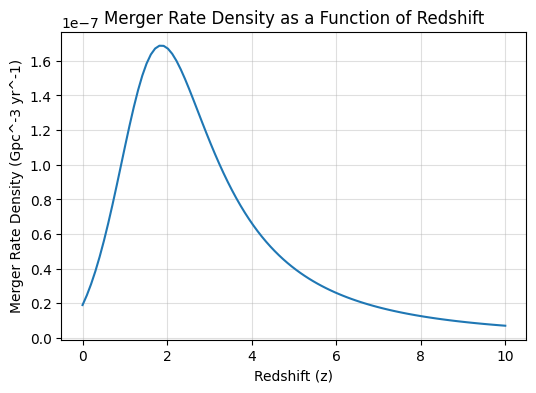

In [10]:
# plot
from matplotlib import pyplot as plt

zs = np.linspace(0, 10, 100)
plt.figure(figsize=(6, 4))
plt.plot(zs, merger_rate_density_madau_dickinson2014_function(zs), color='C0', label='Merger Rate Density')
plt.xlabel('Redshift (z)')
plt.ylabel('Merger Rate Density (Gpc^-3 yr^-1)')
plt.title('Merger Rate Density as a Function of Redshift')
plt.grid(alpha=0.4)
plt.show()

In [14]:
from ler import LeR

ler = LeR(
    npool=6,
    gw_functions = dict(
        merger_rate_density = merger_rate_density_madau_dickinson2014_function,
    ),
    gw_functions_params = dict(
        merger_rate_density = {'param_name': 'merger_rate_density', 'function_type': 'merger_rate_density_madau_dickinson2014_function', 'R0': 19 * 1e-9, 'a': 0.015, 'b': 2.7, 'c': 2.9, 'd': 5.6},
    ),
)


Initializing LeR class...


Initializing LensGalaxyParameterDistribution class...


Initializing OpticalDepth class

comoving_distance interpolator will be loaded from ./interpolator_json/comoving_distance/comoving_distance_0.json
angular_diameter_distance interpolator will be loaded from ./interpolator_json/angular_diameter_distance/angular_diameter_distance_0.json
angular_diameter_distance interpolator will be loaded from ./interpolator_json/angular_diameter_distance/angular_diameter_distance_0.json
differential_comoving_volume interpolator will be loaded from ./interpolator_json/differential_comoving_volume/differential_comoving_volume_0.json
using ler available velocity dispersion function : velocity_dispersion_ewoud
velocity_dispersion_ewoud interpolator will be loaded from ./interpolator_json/velocity_dispersion/velocity_dispersion_ewoud_0.json
using ler available axis_ratio function : rayleigh
rayleigh interpolator will be loaded from ./interpolator_json/axis_ratio/rayleigh_0.j

In [17]:
unlensed_param = ler.unlensed_cbc_statistics(
    size=1000000,
    batch_size=500000,
    resume=False,
    save_batch=False,
    output_jsonfile=False,
)

unlensed params will not be saved to file (output_jsonfile=None/False)
Batch no. 1
sampling gw source params...
calculating pdet...
Batch no. 2
sampling gw source params...
calculating pdet...


In [19]:
unlensed_rate, unlensed_param_det = ler.unlensed_rate(
    unlensed_param=unlensed_param,
    pdet_threshold=0.5,
    pdet_type='boolean',
    output_jsonfile=False,
)

Using provided unlensed_param dict...
total unlensed rate (yr^-1): 375.33512456877
number of simulated unlensed detectable events: 5302
number of simulated all unlensed events: 1000000


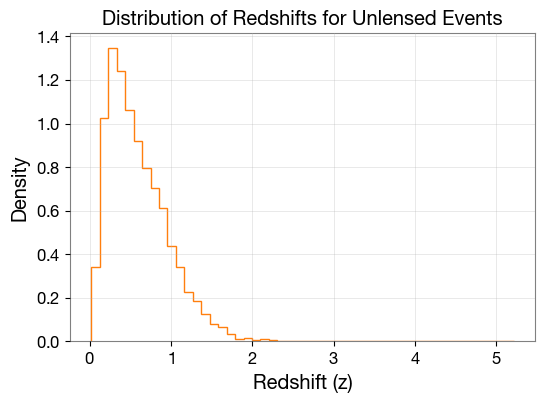

In [22]:
# plot unlensed_param_det
plt.figure(figsize=(6, 4))
plt.hist(unlensed_param_det['zs'], bins=50, density=True, histtype='step', color='C1', label=r'$P(z\mid \text{unlensed})$');
plt.xlabel('Redshift (z)');
plt.ylabel('Density');
plt.title('Distribution of Redshifts for Unlensed Events');
plt.grid(alpha=0.4)
plt.show()